In [1]:
import os

# modules to query skymapper 
import urllib.request

# numeric and table data modules
import numpy as np
import pandas as pd
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# module to read Fits files
from astropy.io import fits

In [2]:
def getKeyVal(filename, keys):
    keys_dict = {}
    with fits.open(filename) as hdu_list:
        primary_header = hdu_list[0].header
        for key in keys:
            keys_dict[key] = primary_header[key]
        return keys_dict

In [3]:
reduced_dir = '/home/fselman/omegacam/fernando/reduced/science/J1649-3307_164955p600_m330702p0/r_SDSS/2017-04-13T05:11:38/'
current_dir = '/home/fselman/omegacam/fernando/'
print('current directory:', os.getcwd())
os.chdir(current_dir)

coord = getKeyVal(reduced_dir+'coadd.fits', ['CRVAL1', 'CRVAL2'])
ra_str = ("%-10.5f" % coord['CRVAL1']).strip()
de_str = ("%-10.5f" % coord['CRVAL2']).strip()
radius = '0.7' 
query_str = "http://skymapper.anu.edu.au/sm-cone/public/query?RA="+ra_str+"&DEC="+de_str+"&SR=0.80&VERB=3&RESPONSEFORMAT=CSV"
print(query_str)
with urllib.request.urlopen(query_str) as f:
    charset = f.headers.get_content_charset()
    # print(charset)
    df_cat = pd.DataFrame([x.split(',') for x in f.read().decode(charset).split('\r\n')])

# we set column 1 as the header collumn
df_cat.columns = df_cat.iloc[0]

# we select only relevant collumns
df_cat = df_cat[['object_id', 'raj2000', 'dej2000', 'class_star', 'g_psf', 'e_g_psf', 'r_psf', 'e_r_psf']][1:]



current directory: /home/fselman/omegacam/mefpp/python
http://skymapper.anu.edu.au/sm-cone/public/query?RA=252.48835&DEC=-33.11324&SR=0.80&VERB=3&RESPONSEFORMAT=CSV


In [4]:
# we convert to numbers where appropriate
df_cat['raj2000']=df_cat.raj2000.replace('',np.nan).astype(float)
df_cat['raj2000'] = df_cat['raj2000'].astype('float64')

df_cat['dej2000']=df_cat.dej2000.replace('',np.nan).astype(float)
df_cat['dej2000'] = df_cat['dej2000'].astype('float64')

df_cat['g_psf'] = df_cat.g_psf.replace('', np.nan).astype('float64')
df_cat['e_g_psf'] = df_cat.e_g_psf.replace('', np.nan).astype('float64')
df_cat['r_psf'] = df_cat.r_psf.replace('', np.nan).astype('float64')
df_cat['e_r_psf'] = df_cat.e_r_psf.replace('', np.nan).astype('float64')

mlim = 17.0
df_cat = df_cat[(df_cat['r_psf'] < mlim) & \
                (df_cat['g_psf'] < mlim) & \
                (df_cat['raj2000'] == df_cat['raj2000']) & \
                (df_cat['dej2000'] == df_cat['dej2000'])]
df_cat

,object_id,raj2000,dej2000,class_star,g_psf,e_g_psf,r_psf,e_r_psf
11,86762410,252.495511,-33.112394,0.983,16.545,0.025,15.381,0.005
14,86762353,252.481821,-33.117257,0.982,16.319,0.043,16.000,0.008
52,86762317,252.472837,-33.120548,0.983,15.757,0.050,15.095,0.003
64,86762366,252.470661,-33.101946,0.979,16.837,0.012,16.292,0.006
85,86762337,252.461565,-33.115608,0.984,16.277,0.013,15.151,0.017
109,86762336,252.457854,-33.110998,0.983,16.374,0.021,15.435,0.021
110,86762348,252.461149,-33.101384,0.984,13.906,0.022,12.882,0.010
140,86762347,252.455801,-33.101354,0.983,14.617,0.007,14.201,0.013
155,86762266,252.494609,-33.144039,0.983,16.512,0.039,15.382,0.017
158,86762233,252.490111,-33.144687,0.983,16.169,0.015,15.572,0.027


In [5]:
# Sanity check: the apertures are on top of the stars...
from astropy import units as u
from astropy.coordinates import SkyCoord
from photutils import SkyCircularAperture
ra = np.array(df_cat['raj2000'])*u.deg
dec = np.array(df_cat['dej2000'])*u.deg

# filter bad coordinates
ra_bad =  np.where(np.isnan(ra))

positions = SkyCoord(ra=ra, dec=dec,frame='icrs')
aperture = SkyCircularAperture(positions, r=2. * u.arcsec)

/opt/anaconda3/lib/python3.6/site-packages/matplotlib/colors.py:527: RuntimeWarning: invalid value encountered in less
  xa[xa < 0] = -1


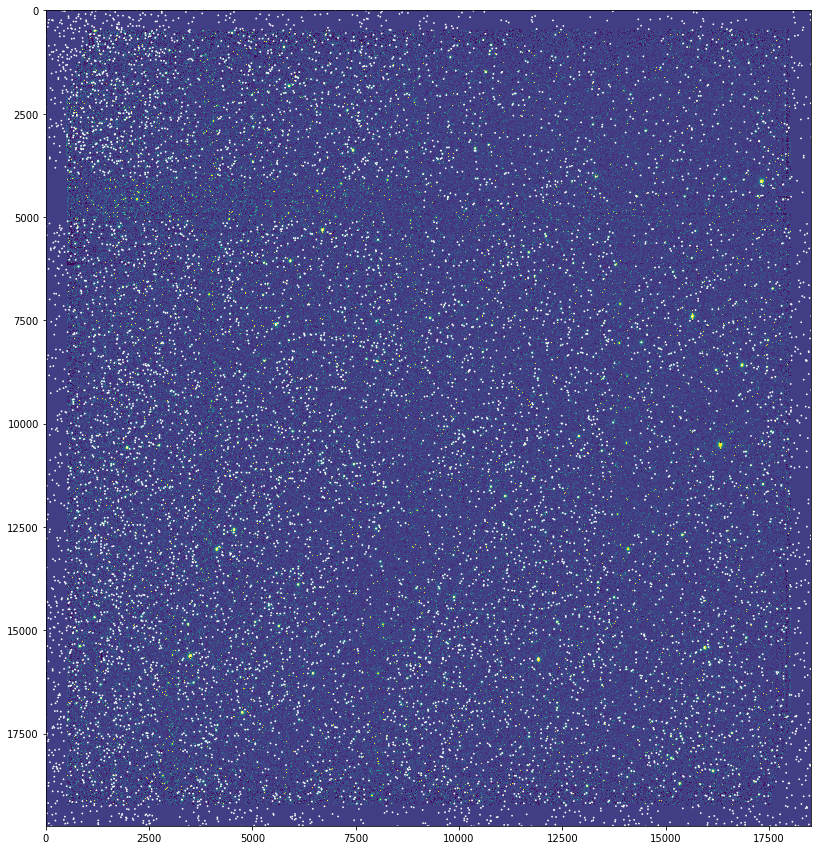

In [6]:
hdu = fits.open(reduced_dir+'coadd.fits')
data = hdu[0].data

import matplotlib.pyplot as plt
from astropy.visualization import simple_norm
from astropy.wcs import WCS
wcs = WCS(reduced_dir+'coadd.fits')  
norm = simple_norm(data, 'sqrt', percent=99)
plt.figure(figsize = (15,15))
plt.imshow(data, norm=norm)
aperture.to_pixel(wcs).plot(color='white', lw=1)
#plt.xlim(5000, 14000)
#plt.ylim(5000, 14000)

/opt/anaconda3/lib/python3.6/site-packages/ipykernel_launcher.py:4: RuntimeWarning: divide by zero encountered in log10
  after removing the cwd from sys.path.
/opt/anaconda3/lib/python3.6/site-packages/ipykernel_launcher.py:4: RuntimeWarning: invalid value encountered in log10
  after removing the cwd from sys.path.


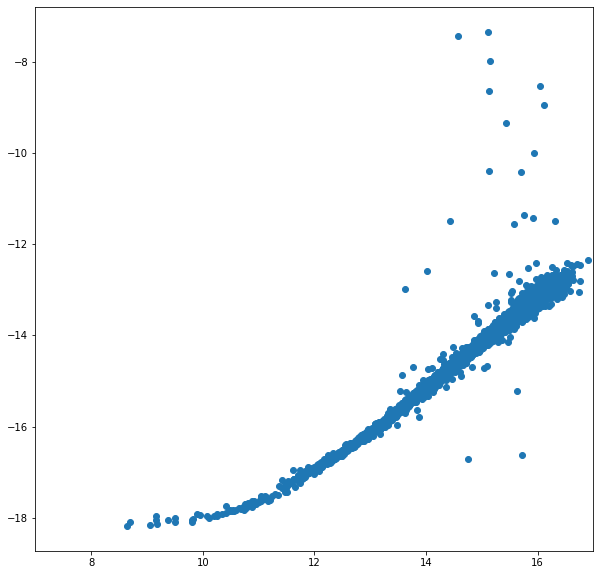

  id       xcenter             ycenter             sky_center      aperture_sum
             pix                 pix                deg,deg                    
----- ------------------ ------------------- --------------------- ------------
    1   9151.19878294104     9880.2875691875 252.495511,-33.112394    319550.51
    2  9344.729107754389   9798.210618790314 252.481821,-33.117257    177409.96
    3  9471.720608929263   9742.651894863848 252.472837,-33.120548    413572.25
    4    9502.5327898307  10056.610933078768 252.470661,-33.101946    133894.02
    5  9631.079301588605   9825.996914962652 252.461565,-33.115608    407354.36
    6  9683.562389877325   9903.790011889032 252.457854,-33.110998    295158.73
    7  9637.022328638632  10066.067583745995 252.461149,-33.101384    3143658.7
    8  9712.636609653387  10066.552394427843 252.455801,-33.101354    886290.36
    9  9163.982248206114   9346.185144675692 252.494609,-33.144039    320825.45
   10  9227.547719678167   9335.25065558

In [7]:
from photutils import aperture_photometry
phot_table = aperture_photometry(data, aperture, wcs=wcs)
phot_table['aperture_sum'].info.format = '%.8g'  # for consistent table output
ocam_r_SDSS = -2.5*np.log10(np.array(phot_table['aperture_sum']))
sm_r_SDSS = np.array(df_cat['r_psf'])
plt.figure(figsize = (10,10))
plt.scatter(sm_r_SDSS, ocam_r_SDSS)
plt.xlim(7.0, 17.0)
#plt.ylim(7, mlim)
plt.show()
print(phot_table)

[  0.98545236 -28.93022016]


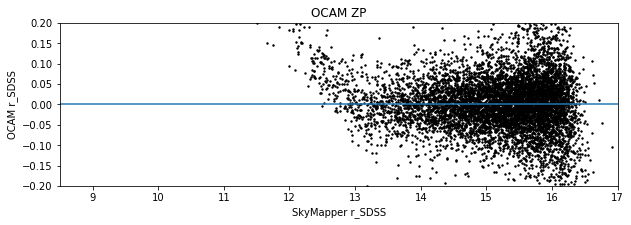

In [8]:
# here we determine the zero point

x = sm_r_SDSS
y = ocam_r_SDSS

X = []
Y = []
for i in range(len(x)):
    if (x[i] == x[i]) and \
        not (np.isinf(y[i]) or np.isnan(y[i])) and \
        (x[i] > 13.5 and x[i] < 15.0):
        X.append(x[i])
        Y.append(y[i])

X = np.array(X)
Y = np.array(Y)
model = np.polyfit(X, Y, 1)

# y = model[0]*x + model[1]
print(model)

# we do one iteration clipping
X1 = []
Y1 = []
for i in range(len(X)):
    ypred = model[0]*X[i] + model[1]
    if np.abs(Y[i] - ypred) < 0.2:
        X1.append(X[i])
        Y1.append(Y[i])

X1 = np.array(X1)
Y1 = np.array(Y1)
model = np.polyfit(X1, Y1, 1)
        

# Plot outputs

plt.figure(figsize = (10,3))
plt.xlim(8.5, 17.0)
plt.ylim(-0.2, 0.2)
plt.scatter(x, y - (model[0]*x+model[1]),  color='black', s=2)
plt.title('OCAM ZP')
plt.xlabel('SkyMapper r_SDSS')
plt.ylabel('OCAM r_SDSS')
plt.axhline(y=0.0)
#plt.xticks(())
#plt.yticks(())

#plt.plot(X1, Y1 - (model[0]*X1+model[1]), color='red',linewidth=2)
plt.show()


# Could not make this work. To continue testing change the cell type from Markdown to Code

from astropy import units as u
from astropy.coordinates import SkyCoord
from astroquery.vo_conesearch import conesearch
from astroquery.vo_conesearch.vos_catalog import VOSDatabase
import warnings

## To explore catalog availability uncomment this file and then go to the cell named explore catalogues...

from astroquery.vo_conesearch.validator import conf as validator_conf
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    registry_db = VOSDatabase.from_registry(
        validator_conf.conesearch_master_list, encoding='binary',
        cache=False)
len(registry_db)    
conesearch.list_catalogs()
## EXPLORE CATALOGS

### the commented lines were used to explore to find the skymapper catalog
#sm_a2_list = registry_db.list_catalogs(pattern='skymapper')
#sm_a2_list
sm_catalog = registry_db.get_catalog('SkyMapper Southern Sky Survey. DR1.1 (Wolf+, 2018) 1')
print(sm_catalog)
#sm_catname = 'SkyMapper Southern Sky Survey. DR1.1 (Wolf+, 2018) 1'
#skymapper_url = 'http://vizier.u-strasbg.fr/viz-bin/conesearch/II/358/smss?'
#sm = registry_db.get_catalog_by_url(skymapper_url)
print(sm)

c = SkyCoord.from_name('CP Pupis')
c
sm_catname = 'SkyMapper Southern Sky Survey. DR1.1 (Wolf+, 2018) 1'
result = conesearch.conesearch(c, 0.1 * u.degree, catalog_db=sm_catname)